# Exploratory Data Analysis on Retail Sales Data

**Project 1 · Oasis Infobyte Data Analytics Internship**

## Objective
Explore transaction, customer demographic, product-category, and sales patterns in the supplied retail dataset, then translate supported findings into practical recommendations.

## Business questions
- How do sales change by month and quarter?
- How are purchases distributed across age groups and gender?
- Which product categories contribute the most transactions and revenue?
- Which numerical fields move together, and what useful pattern appears in an additional view?

## Dataset
The project uses the supplied `retail_sales_dataset.csv`, stored in `data/`. It contains transaction ID, date, customer ID, gender, age, product category, quantity, price per unit, and total amount. The source file was supplied with the project; the suggested Kaggle page is listed in References for provenance. This dataset has category-level labels but no individual product names.


## 1. Imports and display settings

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("data") / "retail_sales_dataset.csv"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")


## 2. Load the data and inspect its structure

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
display(df.describe(include="all").T)


Rows: 1,000 | Columns: 9


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


,dtype,missing
Transaction ID,int64,0
Date,str,0
Customer ID,str,0
Gender,str,0
Age,int64,0
Product Category,str,0
Quantity,int64,0
Price per Unit,int64,0
Total Amount,int64,0


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Transaction ID,"1,000.00",NaN,NaN,NaN,500.50,288.82,1.00,250.75,500.50,750.25,"1,000.00"
Date,1000,345,2023-05-16,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,1000,1000,CUST001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,2,Female,510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"1,000.00",NaN,NaN,NaN,41.39,13.68,18.00,29.00,42.00,53.00,64.00
Product Category,1000,3,Clothing,351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"1,000.00",NaN,NaN,NaN,2.51,1.13,1.00,1.00,3.00,4.00,4.00
Price per Unit,"1,000.00",NaN,NaN,NaN,179.89,189.68,25.00,30.00,50.00,300.00,500.00
Total Amount,"1,000.00",NaN,NaN,NaN,456.00,560.00,25.00,60.00,135.00,900.00,"2,000.00"


## 3. Data cleaning and quality checks

The source has no missing values or exact duplicate rows. Parse `Date` as a date and validate the numeric fields and transaction arithmetic. Keep the original values; do not remove records without evidence of an error. `Customer ID` is unique in this file, so the available rows represent one transaction per customer and do not support repeat-purchase or lifetime-value analysis.


In [3]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
numeric_columns = ["Transaction ID", "Age", "Quantity", "Price per Unit", "Total Amount"]
quality_checks = pd.Series({
    "Unparseable dates": int(df["Date"].isna().sum()),
    "Duplicate transaction IDs": int(df["Transaction ID"].duplicated().sum()),
    "Non-positive quantity": int((df["Quantity"] <= 0).sum()),
    "Non-positive unit price": int((df["Price per Unit"] <= 0).sum()),
    "Non-positive total amount": int((df["Total Amount"] <= 0).sum()),
    "Amount mismatches (quantity × unit price)": int((df["Total Amount"] != df["Quantity"] * df["Price per Unit"]).sum()),
})
display(quality_checks.to_frame("count"))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Unique customers:", df["Customer ID"].nunique())


,count
Unparseable dates,0
Duplicate transaction IDs,0
Non-positive quantity,0
Non-positive unit price,0
Non-positive total amount,0
Amount mismatches (quantity × unit price),0


Date range: 2023-01-01 to 2024-01-01
Unique customers: 1000


## 4. Descriptive statistics

In [4]:
stats = df[numeric_columns].agg(["mean", "median", "std"]).T
stats["mode"] = [df[column].mode().tolist() for column in numeric_columns]
display(stats.rename(columns={"std": "standard deviation"}))


,mean,median,standard deviation,mode
Transaction ID,500.50,500.50,288.82,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
Age,41.39,42.00,13.68,"[43, 64]"
Quantity,2.51,3.00,1.13,[4]
Price per Unit,179.89,50.00,189.68,[50]
Total Amount,456.00,135.00,560.00,[50]


Transaction ID is an identifier, so its summary statistics are included for completeness but are not interpreted as a business measure. Unit price and total amount have means well above their medians, reflecting a right-skewed distribution in this dataset. The mode can contain multiple values when tied (for example, age).


## 5. Monthly and quarterly sales trends

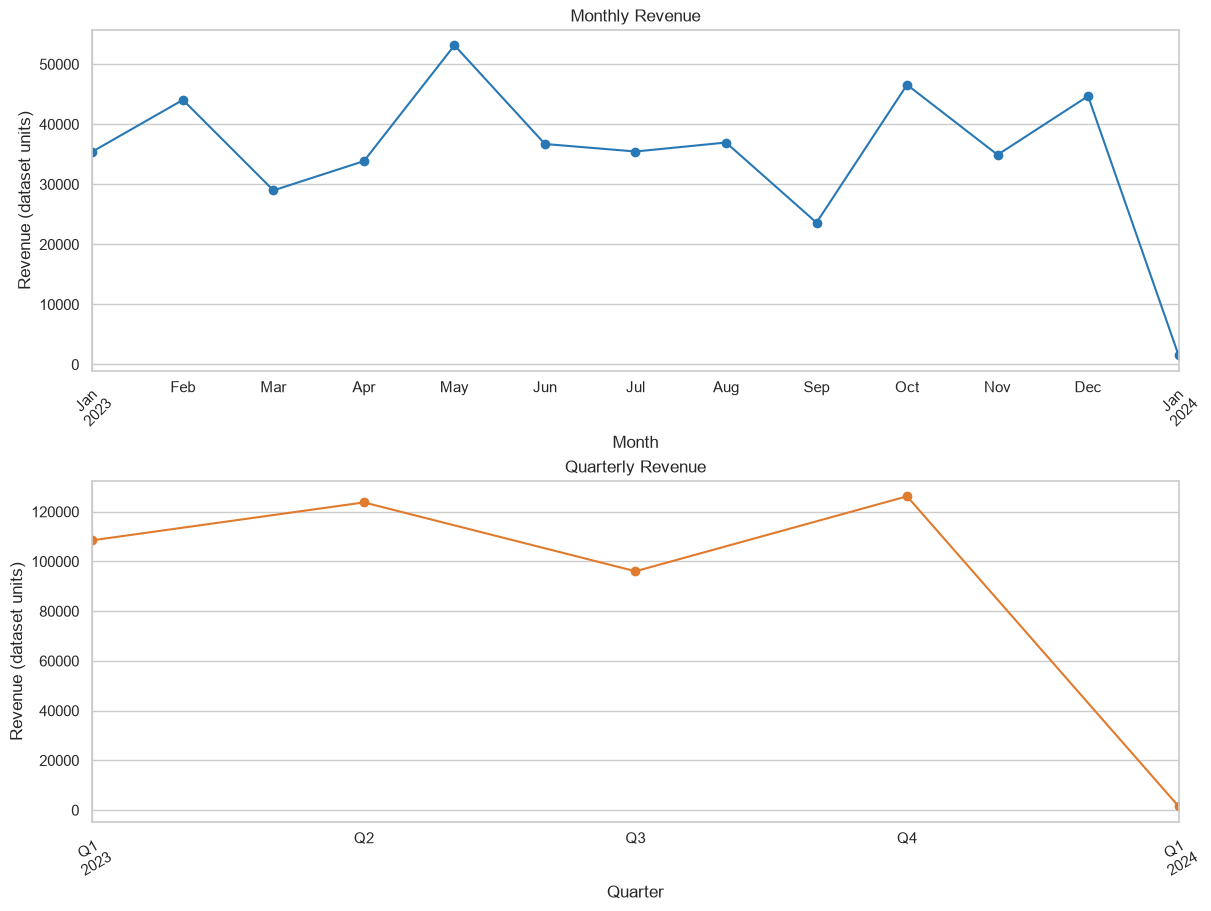

In [5]:
monthly_sales = df.set_index("Date")["Total Amount"].resample("MS").sum()
quarterly_sales = df.set_index("Date")["Total Amount"].resample("QS").sum()

fig, axes = plt.subplots(2, 1, figsize=(12, 9), constrained_layout=True)
monthly_sales.plot(ax=axes[0], marker="o", color="#2878B5")
axes[0].set(title="Monthly Revenue", xlabel="Month", ylabel="Revenue (dataset units)")
axes[0].tick_params(axis="x", rotation=45)
quarterly_sales.plot(ax=axes[1], marker="o", color="#E07A2D")
axes[1].set(title="Quarterly Revenue", xlabel="Quarter", ylabel="Revenue (dataset units)")
axes[1].tick_params(axis="x", rotation=30)
fig.savefig(OUTPUT_DIR / "sales_trends.png", dpi=160, bbox_inches="tight")
plt.show()


**Observation.** Monthly revenue peaks in May 2023 at 53,150 and is lowest in September 2023 at 23,620. The strongest full quarter is Q4 2023 at 126,190, closely followed by Q2 at 123,735. The January 2024 value (1,530) is one transaction on January 1, so it is a partial period and should not be compared directly with full months or quarters. The dataset covers January 2023 through January 1, 2024.


## 6. Customer age-group and gender analysis

,transactions,revenue,average_transaction
Age Group,,,
18–24,149,74650,501.01
25–34,203,97090,478.28
35–44,207,96835,467.80
45–54,225,97235,432.16
55–64,216,90190,417.55


,transactions,revenue,average_transaction
Gender,,,
Female,510,232840,456.55
Male,490,223160,455.43


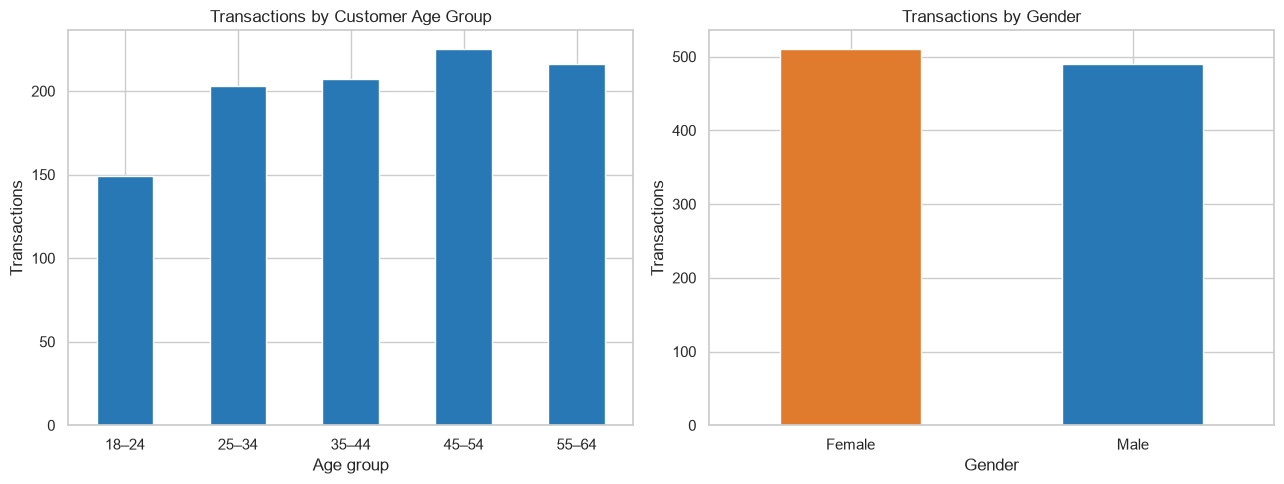

In [6]:
age_bins = [17, 24, 34, 44, 54, 64]
age_labels = ["18–24", "25–34", "35–44", "45–54", "55–64"]
df["Age Group"] = pd.cut(df["Age"], bins=age_bins, labels=age_labels)
age_summary = df.groupby("Age Group", observed=False).agg(
    transactions=("Transaction ID", "count"), revenue=("Total Amount", "sum"), average_transaction=("Total Amount", "mean")
)
gender_summary = df.groupby("Gender").agg(
    transactions=("Transaction ID", "count"), revenue=("Total Amount", "sum"), average_transaction=("Total Amount", "mean")
)
display(age_summary)
display(gender_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
age_summary["transactions"].plot(kind="bar", ax=axes[0], color="#2878B5")
axes[0].set(title="Transactions by Customer Age Group", xlabel="Age group", ylabel="Transactions")
axes[0].tick_params(axis="x", rotation=0)
gender_summary["transactions"].plot(kind="bar", ax=axes[1], color=["#E07A2D", "#2878B5"])
axes[1].set(title="Transactions by Gender", xlabel="Gender", ylabel="Transactions")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "customer_demographics.png", dpi=160, bbox_inches="tight")
plt.show()


**Observation.** Ages 45–54 form the largest transaction group (225 of 1,000); ages 18–24 have the highest mean transaction amount (501.01). Female customers account for 510 transactions and male customers 490, while their mean transaction amounts are nearly identical (456.55 and 455.43). This is descriptive only and does not establish that age or gender causes spending differences.


## 7. Category performance and top categories

,transactions,quantity_sold,revenue
Product Category,,,
Electronics,342,849,156905
Clothing,351,894,155580
Beauty,307,771,143515


The dataset contains category labels but no product/SKU names; category ranking is the finest supported product analysis.


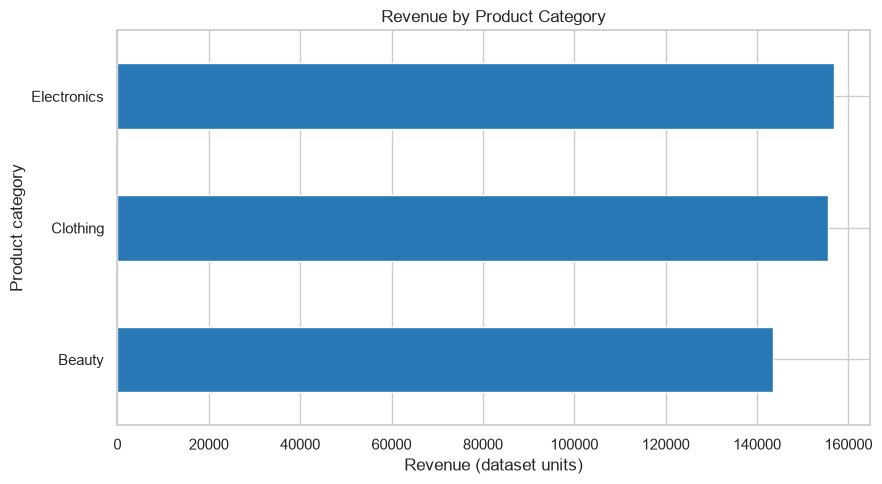

In [7]:
category_summary = df.groupby("Product Category").agg(
    transactions=("Transaction ID", "count"), quantity_sold=("Quantity", "sum"), revenue=("Total Amount", "sum")
).sort_values("revenue", ascending=False)
display(category_summary)
print("The dataset contains category labels but no product/SKU names; category ranking is the finest supported product analysis.")

fig, ax = plt.subplots(figsize=(9, 5))
category_summary["revenue"].sort_values().plot(kind="barh", ax=ax, color="#2878B5")
ax.set(title="Revenue by Product Category", xlabel="Revenue (dataset units)", ylabel="Product category")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "revenue_by_category.png", dpi=160, bbox_inches="tight")
plt.show()


**Observation.** Electronics leads revenue at 156,905, narrowly ahead of Clothing at 155,580; Beauty contributes 143,515. Clothing has the most transactions (351), while Electronics generates slightly more revenue. This supports a category-level comparison only: individual products cannot be ranked because product names are absent.


## 8. Correlation among numerical variables

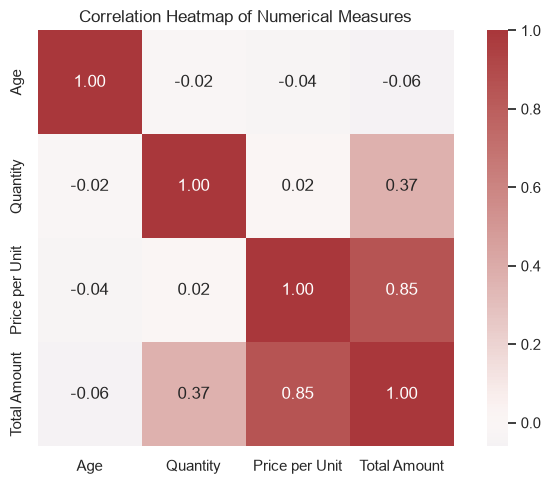

,Age,Quantity,Price per Unit,Total Amount
Age,1.00,-0.02,-0.04,-0.06
Quantity,-0.02,1.00,0.02,0.37
Price per Unit,-0.04,0.02,1.00,0.85
Total Amount,-0.06,0.37,0.85,1.00


In [8]:
correlation_columns = ["Age", "Quantity", "Price per Unit", "Total Amount"]
corr = df[correlation_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True, ax=ax)
ax.set_title("Correlation Heatmap of Numerical Measures")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()
display(corr)


**Observation.** Quantity and total amount have a positive correlation (approximately 0.37), while age and total amount have a weak negative correlation (approximately −0.06). Correlation is descriptive and does not imply causation. `Price per Unit` takes only a few discrete values, and `Total Amount` is mathematically derived from quantity and unit price, so relationships among those fields should be interpreted with that construction in mind.


## 9. Additional view: transaction value by weekday

,transactions,average_transaction,revenue
Weekday,,,
Monday,146,481.16,70250
Tuesday,161,431.30,69440
Wednesday,139,422.81,58770
Thursday,123,437.68,53835
Friday,143,463.57,66290
Saturday,150,525.43,78815
Sunday,138,424.64,58600


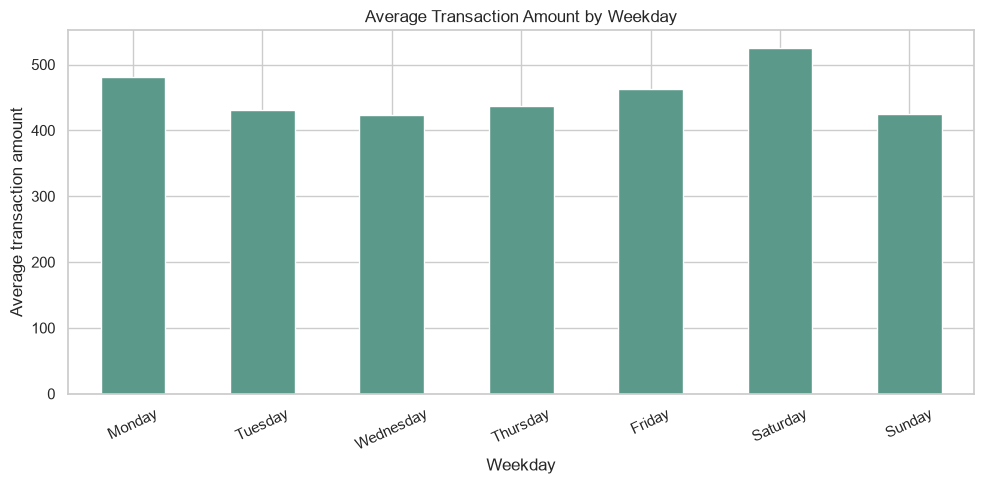

In [9]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = df.assign(Weekday=df["Date"].dt.day_name()).groupby("Weekday").agg(
    transactions=("Transaction ID", "count"), average_transaction=("Total Amount", "mean"), revenue=("Total Amount", "sum")
).reindex(weekday_order)
display(weekday_summary)

fig, ax = plt.subplots(figsize=(10, 5))
weekday_summary["average_transaction"].plot(kind="bar", ax=ax, color="#5B9A8B")
ax.set(title="Average Transaction Amount by Weekday", xlabel="Weekday", ylabel="Average transaction amount")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "weekday_transaction_value.png", dpi=160, bbox_inches="tight")
plt.show()


**Observation.** Saturday has the highest observed mean transaction amount (525.43) and Sunday the lowest (424.64). Saturday also has the largest transaction count (150). This pattern can guide a small, measured weekend campaign, but one year of data is insufficient to establish a stable recurring weekday effect.


## 10. Key findings, limitations, and recommendations

### Key findings
- The dataset contains 1,000 valid transaction rows, 1,000 unique customer IDs, and 456,000 total revenue units.
- Electronics has the highest category revenue; Clothing has the most transactions.
- May 2023 is the strongest month in the observed period. January 2024 is only a single-day partial period.
- Average transaction amounts are similar by gender. Younger age groups show somewhat higher observed average transaction amounts, but this is descriptive.
- Saturday has the highest observed average transaction amount; validate with more periods before treating it as a durable pattern.

### Limitations
- No product/SKU names are present, preventing a top 10 individual-product list.
- Each customer ID appears once, preventing repeat-purchase, retention, or customer lifetime-value analysis.
- Currency is not specified; revenue is reported in the dataset's units without a currency symbol.
- The date range includes a partial January 2024 observation, and the data spans only about one year.
- No discounts, costs, profit, store/channel, or campaign fields are available; revenue does not equal profit.

### Actionable business recommendations
1. **Plan category inventory against revenue and unit movement.** Review Electronics stock and replenishment first because it generated the most revenue (156,905), while monitoring Clothing for volume (894 units and 351 transactions). Track stockouts and margin before changing allocation.
2. **Run a controlled Saturday promotion test.** Compare Saturday basket value and conversion against comparable non-promotion weeks, using a holdout or matched weeks. Saturday's 525.43 average transaction amount is a hypothesis to test, not proof of promotion effectiveness.
3. **Test age-tailored offers with measured outcomes.** Pilot a relevant offer for the 18–24 group, which had the highest average transaction amount (501.01), and compare redemption and incremental revenue against a control group. Avoid gender-based targeting based on these near-equal averages.

## Conclusion
The available data supports a useful transaction-level view of seasonality, customer demographics, category revenue, and weekday basket values. The findings are suitable for planning small experiments and reviewing inventory, while product-level and repeat-customer decisions require richer item and customer history.

## References
- Dataset supplied alongside this project: `data/retail_sales_dataset.csv`.
- Suggested dataset source in the internship specification: [Kaggle — Retail Sales Dataset](https://www.kaggle.com/datasets/mohammadtalib786/retail-sales-dataset).
- Python libraries: pandas, NumPy, Matplotlib, and Seaborn.
